In [1]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam # optimizer
from tensorflow.keras.callbacks import Callback, EarlyStopping
from PIL import Image

# Fix every source of randomness so results can be reproduced
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
DATA_DIR = "split"            
SPLITS = {"train": "train", "val": "validation", "test": "test"}
IMG_EXT = (".pgm")

# ---- Settings ----
IMG_H, IMG_W = 60, 64              # height, width of every image
CLASSES = ["left", "right", "straight", "up"]
NUM_CLASSES = len(CLASSES)

def load_split(folder):
    #Load every image in a folder.

    X, y = [], []
    for root, _, files in os.walk(folder):
        for f in sorted(files):
            if not f.lower().endswith(IMG_EXT):
                continue                                      # skips .bad and other files
            img = np.asarray(Image.open(os.path.join(root, f)).convert("L"), dtype=np.float32)
            if img.shape != (IMG_H, IMG_W):                   # numpy shape is (height, width)
                raise ValueError(f"{f} has shape {img.shape}, expected {(IMG_H, IMG_W)}")
            X.append(img / 255.0)                             # scale pixels to [0, 1]
            y.append(CLASSES.index(os.path.splitext(f)[0].split("_")[1]))
    return np.stack(X)[..., None], np.array(y)               

X_train, y_train = load_split(os.path.join(DATA_DIR, SPLITS["train"]))
X_val,   y_val   = load_split(os.path.join(DATA_DIR, SPLITS["val"]))
X_test,  y_test  = load_split(os.path.join(DATA_DIR, SPLITS["test"]))

print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

Train: (436, 60, 64, 1)  Val: (93, 60, 64, 1)  Test: (95, 60, 64, 1)


In [3]:
# EpochTimer callback to record how long each epoch takes
class EpochTimer(Callback):
    # Records how long each epoch takes.
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self.start)

In [4]:
base_effnet = tf.keras.applications.EfficientNetB0(
    input_shape=(60, 64, 3), include_top=False, weights="imagenet")
base_effnet.trainable = False

model_EffNetB0 = models.Sequential([
    layers.Input(shape=(60, 64, 3)),
    layers.Rescaling(255.0),          # 0–1 → 0–255; EfficientNet normalises internally
    base_effnet,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax"),
], name="EfficientNetB0")

model_EffNetB0.summary()

Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 60, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 2, 2, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [5]:
model_EffNetB0.compile(optimizer=Adam(1e-3),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
timer_head = EpochTimer()
history_EffNetB0_head = model_EffNetB0.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=32, callbacks=[timer_head], verbose=1)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 15s 332ms/step - accuracy: 0.4587 - loss: 1.2344 - val_accuracy: 0.7634 - val_loss: 0.7959
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.6972 - loss: 0.7771 - val_accuracy: 0.8280 - val_loss: 0.5565
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.7821 - loss: 0.5828 - val_accuracy: 0.8710 - val_loss: 0.4292
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.8555 - loss: 0.4675 - val_accuracy: 0.9140 - val_loss: 0.3510
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.8899 - loss: 0.3558 - val_accuracy: 0.9247 - val_loss: 0.2863
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.8991 - loss: 0.3162 - val_accuracy: 0.9785 - val_loss: 0.2185
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.9243 - loss: 0.2861 - val_accuracy: 0.9892 - val_loss: 0.1803
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.9495 - loss: 0.2213 - val_accuracy: 1.0000 -

In [6]:
base_effnet.trainable = True
fine_tune_from = len(base_effnet.layers) - 30
for layer in base_effnet.layers[:fine_tune_from]:
    layer.trainable = False
for layer in base_effnet.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(int(tf.size(w)) for w in model_EffNetB0.trainable_weights)
print(f"Trainable params during fine-tuning: {n_trainable:,}")

model_EffNetB0.compile(optimizer=Adam(1e-5),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
timer_ft = EpochTimer()
history_EffNetB0_ft = model_EffNetB0.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=32, callbacks=[timer_ft], verbose=1)

Trainable params during fine-tuning: 1,647,844
Epoch 1/20


14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 305ms/step - accuracy: 0.9862 - loss: 0.0785 - val_accuracy: 1.0000 - val_loss: 0.0481
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - accuracy: 0.9748 - loss: 0.0788 - val_accuracy: 1.0000 - val_loss: 0.0433
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 1.0000 - loss: 0.0395 - val_accuracy: 1.0000 - val_loss: 0.0366
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.9794 - loss: 0.0686 - val_accuracy: 1.0000 - val_loss: 0.0366
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.9908 - loss: 0.0603 - val_accuracy: 1.0000 - val_loss: 0.0387
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 0.9908 - loss: 0.0510 - val_accuracy: 1.0000 - val_loss: 0.0388
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.9931 - loss: 0.0463 - val_accuracy: 1.0000 - val_loss: 0.0386
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.9885 - loss: 0.0524 - val_accuracy: 0.9785 - val_lo

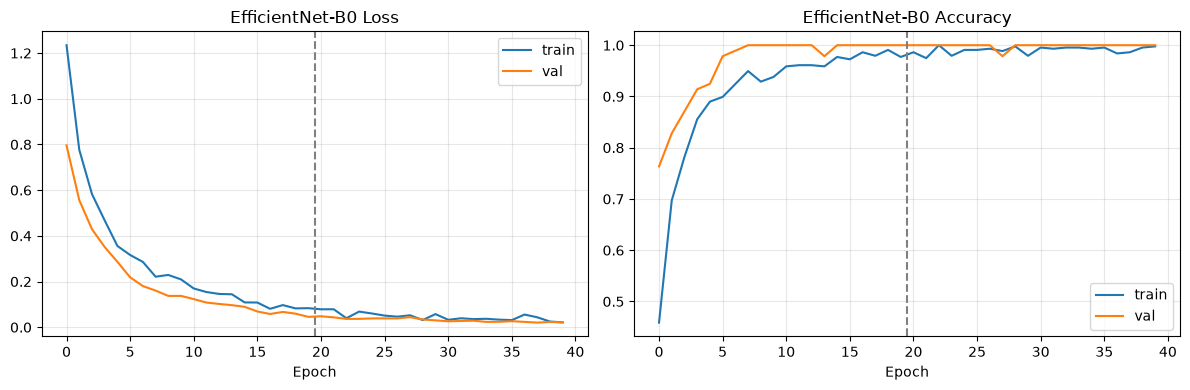

In [7]:

h = {k: history_EffNetB0_head.history[k] + history_EffNetB0_ft.history[k]
     for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(h["loss"], label="train"); ax1.plot(h["val_loss"], label="val")
ax2.plot(h["accuracy"], label="train"); ax2.plot(h["val_accuracy"], label="val")
for ax, t in [(ax1, "Loss"), (ax2, "Accuracy")]:
    ax.axvline(19.5, ls="--", c="gray")           # start of fine-tuning
    ax.set_title(f"EfficientNet-B0 {t}"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [8]:
test_loss_EffNetB0, test_accuracy_EffNetB0 = model_EffNetB0.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss_EffNetB0:.4f}")
print(f"Test Accuracy: {test_accuracy_EffNetB0:.4f}")
print(f"Test Accuracy: {test_accuracy_EffNetB0*100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 1.0000 - loss: 0.0298
Test Loss: 0.0298
Test Accuracy: 1.0000
Test Accuracy: 100.00%


3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step 


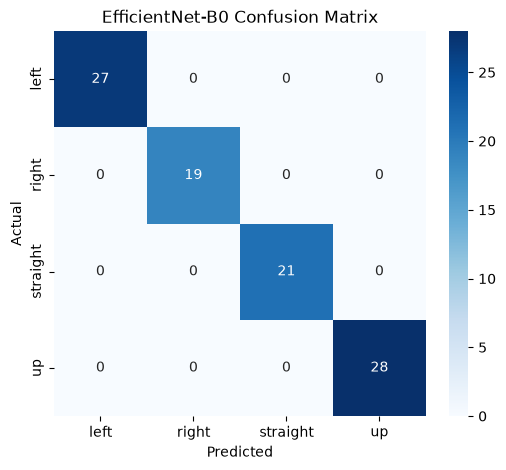

              precision    recall  f1-score   support

        left     1.0000    1.0000    1.0000        27
       right     1.0000    1.0000    1.0000        19
    straight     1.0000    1.0000    1.0000        21
          up     1.0000    1.0000    1.0000        28

    accuracy                         1.0000        95
   macro avg     1.0000    1.0000    1.0000        95
weighted avg     1.0000    1.0000    1.0000        95



In [9]:
y_pred_prob_EffNetB0 = model_EffNetB0.predict(X_test)
y_pred_EffNetB0 = np.argmax(y_pred_prob_EffNetB0, axis=1)

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_EffNetB0)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNet-B0 Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred_EffNetB0,
    target_names=CLASSES,
    digits=4
))

In [10]:
model_EffNetB0.save_weights("EfficientNetB0_CMU_Face.weights.h5")
print(f"Total params:        {model_EffNetB0.count_params():,}")
print(f"Size on disk:        {os.path.getsize('EfficientNetB0_CMU_Face.weights.h5')/1024:.1f} KB")
print(f"s/epoch (head):      {np.mean(timer_head.times[1:]):.3f}")
print(f"s/epoch (fine-tune): {np.mean(timer_ft.times[1:]):.3f}")

Total params:        4,214,055
Size on disk:        29957.5 KB
s/epoch (head):      1.180
s/epoch (fine-tune): 1.580
